# Mass-spring-damper: verified tracking-error bounds

dynacert version of cp_reach's `examples/general/structured_workflow.ipynb`.

1. The Modelica model is annotated with the specification: disturbance bound, reference relations, and the outputs to certify.
2. `dynacert.check` runs rumoca, which exports the model to Lean and to sympy from one DAE IR. It then derives the error dynamics, searches for a certificate (untrusted), and has the Lean kernel check the resulting theorem.
3. We simulate the Modelica model under admissible inputs and plot the trajectories against the **verified** bounds.

Only the Lean theorem is trusted. The search and the simulations are untrusted Python.

In [1]:
import dynacert
from pathlib import Path
from IPython.display import Markdown, display

root = dynacert.find_root()
examples = root / "examples"
print("dynacert project:", root)

dynacert project: /home/micah/Research/development/dynacert


## The model

cp_reach's `closed_loop.mo` (m = 1, c = 0.2, k = 1, kp = 2, kd = 0.8), with the feedforward computed in the model and the reference declared.

In [2]:
display(Markdown("```modelica\n" + (examples / "ClosedLoop.mo").read_text() + "\n```"))

```modelica
// cp_reach examples/general/models/closed_loop.mo, with the feedforward computed in the
// model (u_ff = m a_ref + c v_ref + k x_ref) instead of supplied as a free input, and the
// reference trajectory declared: x_ref' = v_ref, v_ref' = a_ref, starting at rest.
model ClosedLoop
  parameter Real m = 1.0 "Mass [kg]";
  parameter Real c = 0.2 "Damping coefficient [N*s/m]";
  parameter Real k = 1.0 "Spring constant [N/m]";
  parameter Real kp = 2.0 "Proportional gain";
  parameter Real kd = 0.8 "Derivative gain";

  input Real x_ref "Reference position [m]"
    annotation(__Dynacert(reference(derivative = "v_ref", start = 0)));
  input Real v_ref "Reference velocity [m/s]"
    annotation(__Dynacert(reference(derivative = "a_ref", start = 0)));
  input Real a_ref "Reference acceleration [m/s2]" annotation(__Dynacert(reference));
  input Real d "Disturbance force [N]" annotation(__Dynacert(disturbance(bound = 1.0)));

  Real x(start = 0, fixed = true) "Position [m]";
  Real v(start = 0, fixed = true) "Velocity [m/s]";

  Real u_ff "Feedforward force [N]";
  Real F "Control force [N]";
  Real e "Position error [m]" annotation(__Dynacert(certify));
  Real ev "Velocity error [m/s]" annotation(__Dynacert(certify));
equation
  e = x - x_ref;
  ev = v - v_ref;
  u_ff = m*a_ref + c*v_ref + k*x_ref;
  F = u_ff - kp*e - kd*ev;
  der(x) = v;
  der(v) = (F + d - c*v - k*x) / m;
end ClosedLoop;

```

## Certify

`check` regenerates `certs/Certs/ClosedLoop/{Model,Spec,Cert}.lean`, builds them with Lean, and audits the axioms of the final theorem.

In [3]:
cert = dynacert.check(examples / "ClosedLoop.mo", "ClosedLoop")
cert

rumoca: exporting ClosedLoop (lean-dae, sympy-dae)
spec: disturbances [('d', '1')], certify ['e', 'ev']
model: LTI, n = 2, m = 1


search: α = 0.4778, level = 2.06791
lean: lake build Certs.ClosedLoop.Cert


lean: ClosedLoop.Cert.certified checked; axioms ['Classical.choice', 'Quot.sound', 'propext']


**ClosedLoop**: `ClosedLoop.Cert.certified : Spec.Claim ...`, checked by the Lean kernel (axioms: Classical.choice, Quot.sound, propext)

| output | verified bound | ≈ |
|---|---|---|
| `e` | `5649/6695` | 0.843764 |
| `ev` | `7281/5089` | 1.43073 |

```lean
def Claim (b : Fin 2 → ℚ) : Prop :=
  ∀ (p : Params) (u : ℝ → Inputs) (x : ℝ → States) (y : ℝ → Algebraics) (T : ℝ),
    p.Bound → IsSolutionOn p u x y T → Admissible u T → References u T →
    ReferenceStart u → Initial p (x 0) →
    (∀ t ∈ Ico 0 T, |(y t).e| ≤ (b 0 : ℝ) ∧ |(y t).ev| ≤ (b 1 : ℝ))
```

### What is proved

The claim's hypotheses, from `Spec.lean`. They are generated from the annotations only.

In [4]:
display(Markdown("```lean\n" + cert.hypotheses + "\n```"))

```lean
/-- Admissible disturbances: componentwise peak bounds. -/
def Admissible (u : ℝ → Inputs) (T : ℝ) : Prop :=
  ∀ t ∈ Ico 0 T, |(u t).d| ≤ (1 : ℝ)

/-- Reference signals: continuous on `[0, T]` with the declared right
derivatives on `[0, T)`. -/
def References (u : ℝ → Inputs) (T : ℝ) : Prop :=
  ContinuousOn (fun s => (u s).x_ref) (Icc 0 T) ∧
  ContinuousOn (fun s => (u s).v_ref) (Icc 0 T) ∧
  ∀ t ∈ Ico 0 T, HasDerivWithinAt (fun s => (u s).x_ref) (u t).v_ref (Ici t) t ∧
    HasDerivWithinAt (fun s => (u s).v_ref) (u t).a_ref (Ici t) t

/-- Reference values at `t = 0`. -/
def ReferenceStart (u : ℝ → Inputs) : Prop :=
  (u 0).x_ref = (0 : ℝ) ∧ (u 0).v_ref = (0 : ℝ)
```

Re-check the theorem with the Lean kernel at any time:

In [5]:
cert.verify()

ClosedLoop.Cert.certified: checked by the Lean kernel; axioms ['Classical.choice', 'Quot.sound', 'propext']


['Classical.choice', 'Quot.sound', 'propext']

## Simulations vs. verified bounds

The simulations run the Modelica equations (from rumoca's sympy export).

- **Disturbances:** bang-bang, sinusoidal, and random steps, all with |d| ≤ 1.
- **References:** a random smooth `a_ref`, integrated to `v_ref` and `x_ref` from rest, as the claim assumes.

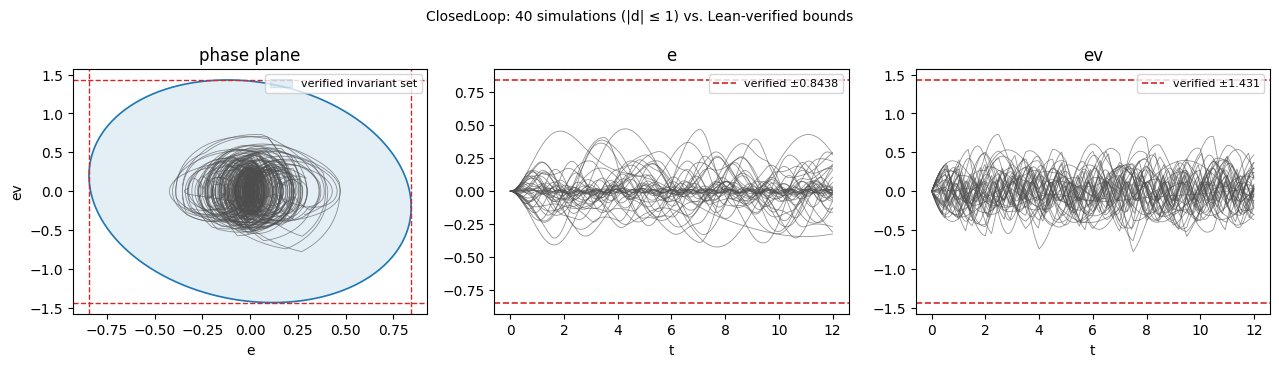

In [6]:
runs = cert.simulate(40, T=12)
fig = cert.plot(runs)

In [7]:
cert.table(runs)

,verified bound,≈,simulated peak,peak / bound
output,,,,
e,5649/6695,0.843764,0.473446,0.561112
ev,7281/5089,1.430733,0.776345,0.542620


## Comparison with cp_reach

cp_reach's notebook reports `bounds_upper: [0.84309921, 1.42957659]` for this model. dynacert's bounds come out about 0.1% larger: it rounds to exact rationals with a small margin so that the kernel check succeeds.

In [8]:
cp_reach = {"e": 0.84309921, "ev": 1.42957659}
for name, b in cert.bounds.items():
    print(f"{name:3s} dynacert {float(b):.6f}   cp_reach {cp_reach[name]:.6f}   ratio {float(b) / cp_reach[name]:.5f}")

e   dynacert 0.843764   cp_reach 0.843099   ratio 1.00079
ev  dynacert 1.430733   cp_reach 1.429577   ratio 1.00081


## Component model: error dynamics derived from the model

cp_reach's `closed_loop_composed.mo` (plant + PD controller components, kp = 10, kd = 2), with the same three changes as above. dynacert takes the certified outputs `e = plant.x - x_ref` and `ev = plant.v - v_ref` as coordinates and derives ż = A z + B d from the equations. Lean then proves each derivative identity from rumoca's equations.

In [9]:
composed = dynacert.check(examples / "ClosedLoopComposed.mo", "ClosedLoopComposed")
composed

rumoca: exporting ClosedLoopComposed (lean-dae, sympy-dae)
spec: disturbances [('d', '1')], certify ['e', 'ev']


model: LTI, n = 2, m = 1


search: α = 1.056, level = 0.426926
lean: lake build Certs.ClosedLoopComposed.Cert


lean: ClosedLoopComposed.Cert.certified checked; axioms ['Classical.choice', 'Quot.sound', 'propext']


**ClosedLoopComposed**: `ClosedLoopComposed.Cert.certified : Spec.Claim ...`, checked by the Lean kernel (axioms: Classical.choice, Quot.sound, propext)

| output | verified bound | ≈ |
|---|---|---|
| `e` | `17/84` | 0.202381 |
| `ev` | `1185/1816` | 0.652533 |

```lean
def Claim (b : Fin 2 → ℚ) : Prop :=
  ∀ (p : Params) (u : ℝ → Inputs) (x : ℝ → States) (y : ℝ → Algebraics) (T : ℝ),
    p.Bound → IsSolutionOn p u x y T → Admissible u T → References u T →
    ReferenceStart u → Initial p (x 0) →
    (∀ t ∈ Ico 0 T, |(y t).e| ≤ (b 0 : ℝ) ∧ |(y t).ev| ≤ (b 1 : ℝ))
```

In [10]:
print("derived A =", composed.sidecar["A"], "  B =", composed.sidecar["B"])
src = (composed.dir / "Cert.lean").read_text()
step = src[src.index("    · show HasDerivWithinAt (fun s => (1 : ℝ) * (x s).«plant.v»"):src.index("/-! ### Storage")]
display(Markdown("One step of the generated link proof (Lean):\n```lean\n" + step.strip() + "\n```"))

derived A = [['0', '1'], ['-11', '-11/5']]   B = [['0'], ['1']]


One step of the generated link proof (Lean):
```lean
· show HasDerivWithinAt (fun s => (1 : ℝ) * (x s).«plant.v» + (-1 : ℝ) * (u s).v_ref) _ (Ici t) t
      refine (((hd1.const_mul (1 : ℝ))).add (hrd1.const_mul (-1 : ℝ))).congr_deriv ?_
      rw [f_apply]
      show (1 : ℝ) * (dx t).«plant.v» + (-1 : ℝ) * (u t).a_ref = (-11 : ℝ) * ((1 : ℝ) * (x t).«plant.x» + (-1 : ℝ) * (u t).x_ref) + (-11/5 : ℝ) * ((1 : ℝ) * (x t).«plant.v» + (-1 : ℝ) * (u t).v_ref) + (1 : ℝ) * ((u t).d)
      linear_combination (1 : ℝ) * e1 + (-10 : ℝ) * e2 + (-2 : ℝ) * e3 + (-10 : ℝ) * e4 + (-2 : ℝ) * e5 + (1 : ℝ) * e6 + (-10 : ℝ) * e7 + (-2 : ℝ) * e8 + (1 : ℝ) * e9 + (10 : ℝ) * e10 + (2 : ℝ) * e11 + (1 : ℝ) * e12 + (1 : ℝ) * e13 + (1 : ℝ) * e14
```

,verified bound,≈,simulated peak,peak / bound
output,,,,
e,17/84,0.202381,0.160485,0.792986
ev,1185/1816,0.652533,0.540187,0.827831


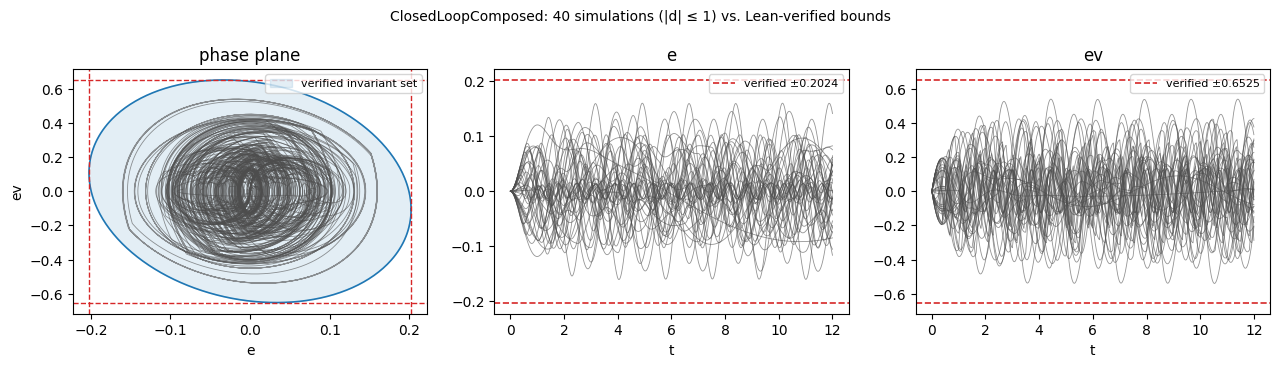

In [11]:
runs_c = composed.simulate(40, T=12)
fig = composed.plot(runs_c)
composed.table(runs_c)

## Parameter uncertainty

The same closed loop, with damping `c ∈ [0.1, 0.3]` (`__Dynacert(uncertain(min = 0.1, max = 0.3))`). The claim now quantifies over every damping value in the interval. The proof is a common Lyapunov function over the vertices of the parameter box. In the simulations, the damping is sampled in the interval, including the endpoints.

In [12]:
unc = dynacert.check(examples / "ClosedLoopUncertain.mo", "ClosedLoopUncertain")
unc

rumoca: exporting ClosedLoopUncertain (lean-dae, sympy-dae)
spec: disturbances [('d', '1')], certify ['e', 'ev']


model: LTI, n = 2, m = 1


search: α = 0.4186, level = 2.54614
lean: lake build Certs.ClosedLoopUncertain.Cert


lean: ClosedLoopUncertain.Cert.certified checked; axioms ['Classical.choice', 'Quot.sound', 'propext']


**ClosedLoopUncertain**: `ClosedLoopUncertain.Cert.certified : Spec.Claim ...`, checked by the Lean kernel (axioms: Classical.choice, Quot.sound, propext)

| output | verified bound | ≈ |
|---|---|---|
| `e` | `1349/1445` | 0.933564 |
| `ev` | `14619/9197` | 1.58954 |

```lean
def Claim (b : Fin 2 → ℚ) : Prop :=
  ∀ (p : Params) (u : ℝ → Inputs) (x : ℝ → States) (y : ℝ → Algebraics) (T : ℝ),
    ParamsOK p → IsSolutionOn p u x y T → Admissible u T → References u T →
    ReferenceStart u → Initial p (x 0) →
    (∀ t ∈ Ico 0 T, |(y t).e| ≤ (b 0 : ℝ) ∧ |(y t).ev| ≤ (b 1 : ℝ))
```

,verified bound,≈,simulated peak,peak / bound
output,,,,
e,1349/1445,0.933564,0.686340,0.735182
ev,14619/9197,1.589540,1.162587,0.731398


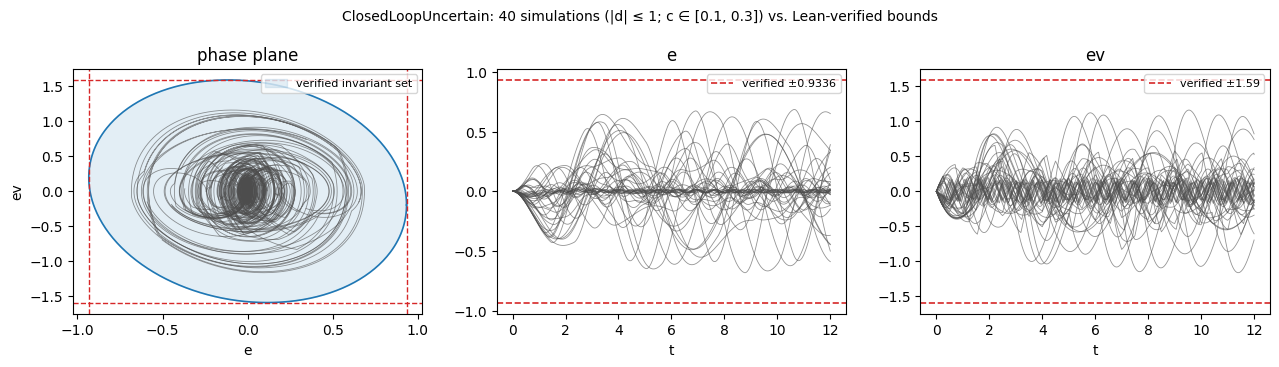

In [13]:
runs_u = unc.simulate(40, T=12)
fig = unc.plot(runs_u)
unc.table(runs_u)